<a href="https://colab.research.google.com/github/krishnanpatil1212/SmartPrice-AI-Smartphone-Price-Range-Predictor/blob/main/SmartPrice_AI_%E2%80%93_Smartphone_Price_Range_Predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Step 1: Import Required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")


All libraries imported successfully!


In [6]:

# Step 2: Upload and Load Smartphone Dataset

import os
import zipfile
import pandas as pd
from google.colab import files

# Upload dataset ZIP file
uploaded = files.upload()

zip_file = list(uploaded.keys())[0]

# Extract ZIP file
with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('extracted_files')

# Locate and load CSV files
train_path = 'extracted_files/train.csv'
test_path = 'extracted_files/test.csv'

if os.path.exists(train_path) and os.path.exists(test_path):

    train_df = pd.read_csv(train_path)
    test_df = pd.read_csv(test_path)

    print("Datasets loaded successfully!")
    print("Training Set Shape:", train_df.shape)
    print("Testing Set Shape:", test_df.shape)

    print("\n--- First 5 Rows of Training Set ---")
    display(train_df.head())

else:
    print("Error: CSV files not found. Check the ZIP file structure.")


Saving archive.zip to archive (1).zip
Datasets loaded successfully!
Training Set Shape: (2000, 21)
Testing Set Shape: (1000, 21)

--- First 5 Rows of Training Set ---


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [7]:

# Step 3: Dataset Inspection and Exploratory Data Analysis

# Display dataset information
print("--- Dataset Information ---")
train_df.info()

# Check dataset dimensions
print("\nDataset Shape:", train_df.shape)

# Check column names
print("\n--- Column Names ---")
print(train_df.columns.tolist())

# Statistical summary
print("\n--- Statistical Summary ---")
display(train_df.describe())

# Check missing values
print("\n--- Missing Values ---")
print(train_df.isnull().sum())

# Check duplicate records
print("\nNumber of Duplicate Rows:", train_df.duplicated().sum())

# Check target class distribution
print("\n--- Price Range Distribution ---")
print(train_df['price_range'].value_counts().sort_index())


--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,...,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,...,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,...,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000



--- Missing Values ---
battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64

Number of Duplicate Rows: 0

--- Price Range Distribution ---
price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64


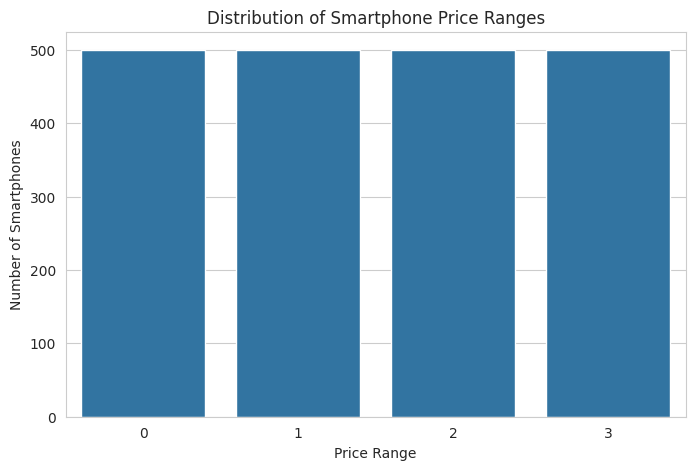

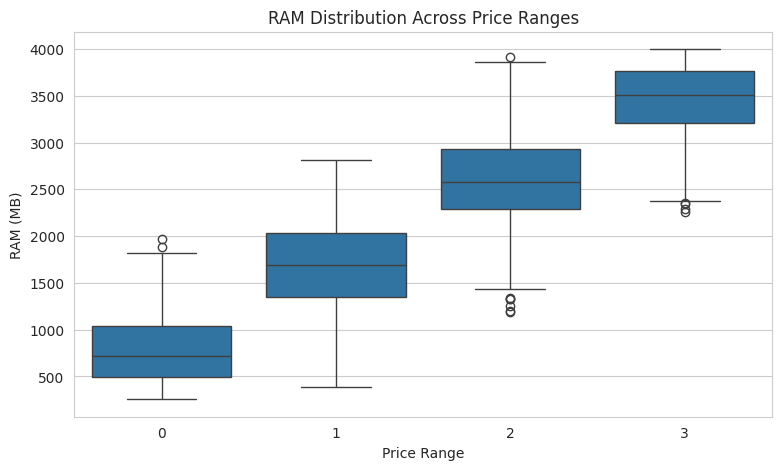

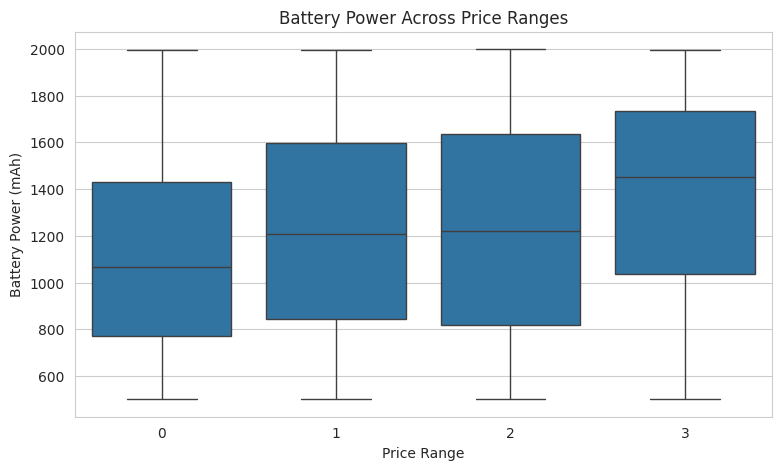

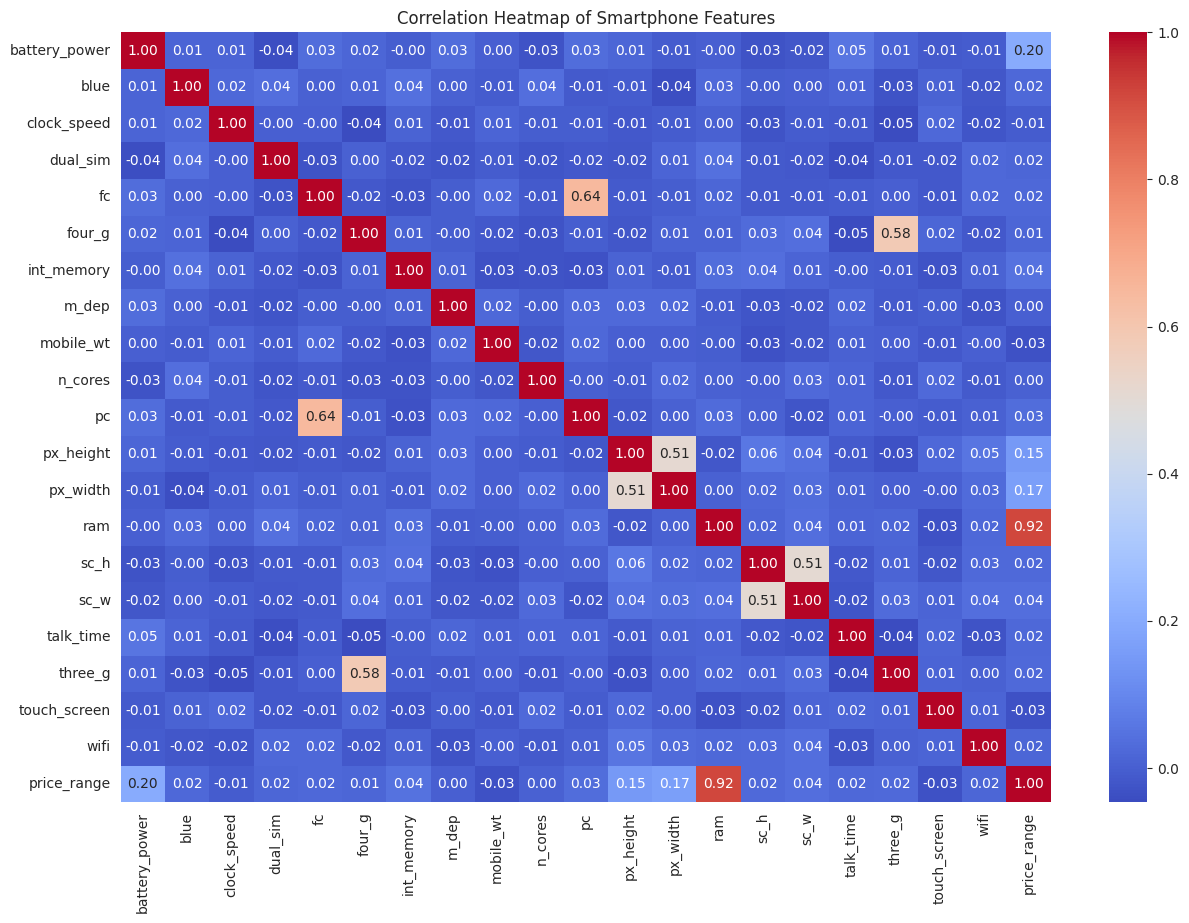

In [8]:

# Step 4: Exploratory Data Visualization

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# 1. Distribution of Smartphone Price Ranges
plt.figure(figsize=(8, 5))
sns.countplot(data=train_df, x='price_range')
plt.title('Distribution of Smartphone Price Ranges')
plt.xlabel('Price Range')
plt.ylabel('Number of Smartphones')
plt.show()


# 2. RAM vs Price Range
plt.figure(figsize=(9, 5))
sns.boxplot(data=train_df, x='price_range', y='ram')
plt.title('RAM Distribution Across Price Ranges')
plt.xlabel('Price Range')
plt.ylabel('RAM (MB)')
plt.show()


# 3. Battery Power vs Price Range
plt.figure(figsize=(9, 5))
sns.boxplot(data=train_df, x='price_range', y='battery_power')
plt.title('Battery Power Across Price Ranges')
plt.xlabel('Price Range')
plt.ylabel('Battery Power (mAh)')
plt.show()


# 4. Correlation Heatmap
plt.figure(figsize=(15, 10))
correlation = train_df.drop(columns=['id'], errors='ignore').corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Smartphone Features')
plt.show()


In [9]:

# Step 5: Data Preprocessing and Feature Selection

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate input features and target variable
X = train_df.drop(columns=['price_range', 'id'], errors='ignore')
y = train_df['price_range']

# Check missing values
print("Missing Values:", X.isnull().sum().sum())

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Standardize features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nData preprocessing completed successfully!")
print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)


Missing Values: 0

Data preprocessing completed successfully!
Training Features Shape: (1600, 20)
Testing Features Shape: (400, 20)
Training Target Shape: (1600,)
Testing Target Shape: (400,)


In [10]:

# Step 6: Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report

# Initialize Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)

# Define hyperparameter grid
dt_params = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# 5-Fold Stratified Cross Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Hyperparameter tuning
dt_grid = GridSearchCV(
    dt_model,
    dt_params,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

# Best model
best_dt = dt_grid.best_estimator_

# Predictions
dt_predictions = best_dt.predict(X_test)

# Evaluation
dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Decision Tree Classifier Results")
print("--------------------------------")
print("Best Parameters:", dt_grid.best_params_)
print("Best Cross-Validation Accuracy:", round(dt_grid.best_score_ * 100, 2), "%")
print("Test Accuracy:", round(dt_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, dt_predictions))


Decision Tree Classifier Results
--------------------------------
Best Parameters: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2}
Best Cross-Validation Accuracy: 84.44 %
Test Accuracy: 86.75 %

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.96      0.94       100
           1       0.82      0.78      0.80       100
           2       0.80      0.80      0.80       100
           3       0.93      0.93      0.93       100

    accuracy                           0.87       400
   macro avg       0.87      0.87      0.87       400
weighted avg       0.87      0.87      0.87       400



In [11]:

# Step 7: Gaussian Naive Bayes Classifier

from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, classification_report

# Initialize Gaussian Naive Bayes
nb_model = GaussianNB()

# Perform 5-Fold Cross Validation
nb_cv_scores = cross_val_score(
    nb_model,
    X_train_scaled,
    y_train,
    cv=cv,
    scoring='accuracy'
)

# Train the model
nb_model.fit(X_train_scaled, y_train)

# Make predictions
nb_predictions = nb_model.predict(X_test_scaled)

# Evaluate the model
nb_accuracy = accuracy_score(y_test, nb_predictions)

print("Gaussian Naive Bayes Results")
print("--------------------------------")
print("Cross-Validation Accuracy:",
      round(nb_cv_scores.mean() * 100, 2), "%")
print("Test Accuracy:",
      round(nb_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, nb_predictions))


Gaussian Naive Bayes Results
--------------------------------
Cross-Validation Accuracy: 80.38 %
Test Accuracy: 81.0 %

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.90      0.91       100
           1       0.71      0.69      0.70       100
           2       0.70      0.73      0.71       100
           3       0.91      0.92      0.92       100

    accuracy                           0.81       400
   macro avg       0.81      0.81      0.81       400
weighted avg       0.81      0.81      0.81       400



In [12]:

# Step 8: Linear Support Vector Machine (SVM)

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report

# Initialize Linear SVM
linear_svm = SVC(kernel='linear')

# Define hyperparameter grid
linear_params = {
    'C': [0.1, 1, 10, 100]
}

# Perform GridSearchCV with 5-Fold Cross Validation
linear_grid = GridSearchCV(
    linear_svm,
    linear_params,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

# Train the model
linear_grid.fit(X_train_scaled, y_train)

# Get best model
best_linear_svm = linear_grid.best_estimator_

# Make predictions
linear_predictions = best_linear_svm.predict(X_test_scaled)

# Evaluate the model
linear_accuracy = accuracy_score(y_test, linear_predictions)

print("Linear SVM Results")
print("--------------------------------")
print("Best Parameters:", linear_grid.best_params_)
print("Best Cross-Validation Accuracy:",
      round(linear_grid.best_score_ * 100, 2), "%")
print("Test Accuracy:",
      round(linear_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, linear_predictions))


Linear SVM Results
--------------------------------
Best Parameters: {'C': 10}
Best Cross-Validation Accuracy: 96.38 %
Test Accuracy: 97.5 %

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.98       100
           1       0.97      0.96      0.96       100
           2       0.96      0.97      0.97       100
           3       0.98      0.99      0.99       100

    accuracy                           0.97       400
   macro avg       0.98      0.98      0.97       400
weighted avg       0.98      0.97      0.97       400



In [13]:

# Step 9: RBF Kernel Support Vector Machine (SVM)

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report

# Initialize RBF SVM
rbf_svm = SVC(kernel='rbf')

# Define hyperparameter grid
rbf_params = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1]
}

# Perform GridSearchCV with 5-Fold Cross Validation
rbf_grid = GridSearchCV(
    rbf_svm,
    rbf_params,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

# Train the model
rbf_grid.fit(X_train_scaled, y_train)

# Get best model
best_rbf_svm = rbf_grid.best_estimator_

# Make predictions
rbf_predictions = best_rbf_svm.predict(X_test_scaled)

# Evaluate the model
rbf_accuracy = accuracy_score(y_test, rbf_predictions)

print("RBF SVM Results")
print("--------------------------------")
print("Best Parameters:", rbf_grid.best_params_)
print("Best Cross-Validation Accuracy:",
      round(rbf_grid.best_score_ * 100, 2), "%")
print("Test Accuracy:",
      round(rbf_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, rbf_predictions))


RBF SVM Results
--------------------------------
Best Parameters: {'C': 10, 'gamma': 0.01}
Best Cross-Validation Accuracy: 90.88 %
Test Accuracy: 94.0 %

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95       100
           1       0.93      0.90      0.91       100
           2       0.93      0.93      0.93       100
           3       0.95      0.98      0.97       100

    accuracy                           0.94       400
   macro avg       0.94      0.94      0.94       400
weighted avg       0.94      0.94      0.94       400



In [14]:

# Step 10: K-Nearest Neighbors (KNN) Classifier

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report

# Initialize KNN
knn_model = KNeighborsClassifier()

# Define hyperparameter grid
knn_params = {
    'n_neighbors': [3, 5, 7, 9, 11, 13, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

# Perform GridSearchCV with 5-Fold Cross Validation
knn_grid = GridSearchCV(
    knn_model,
    knn_params,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

# Train the model
knn_grid.fit(X_train_scaled, y_train)

# Get best model
best_knn = knn_grid.best_estimator_

# Make predictions
knn_predictions = best_knn.predict(X_test_scaled)

# Evaluate the model
knn_accuracy = accuracy_score(y_test, knn_predictions)

print("KNN Classifier Results")
print("--------------------------------")
print("Best Parameters:", knn_grid.best_params_)
print("Best Cross-Validation Accuracy:",
      round(knn_grid.best_score_ * 100, 2), "%")
print("Test Accuracy:",
      round(knn_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, knn_predictions))



KNN Classifier Results
--------------------------------
Best Parameters: {'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'distance'}
Best Cross-Validation Accuracy: 60.69 %
Test Accuracy: 64.25 %

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.82      0.80       100
           1       0.58      0.53      0.55       100
           2       0.51      0.52      0.51       100
           3       0.70      0.70      0.70       100

    accuracy                           0.64       400
   macro avg       0.64      0.64      0.64       400
weighted avg       0.64      0.64      0.64       400



Performance Comparison of Machine Learning Algorithms


,Algorithm,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.8675,0.8663,0.8675,0.8666
1,Gaussian Naive Bayes,0.8100,0.8113,0.8100,0.8105
2,Linear SVM,0.9750,0.9750,0.9750,0.9750
3,RBF SVM,0.9400,0.9398,0.9400,0.9398
4,KNN,0.6425,0.6399,0.6425,0.6408


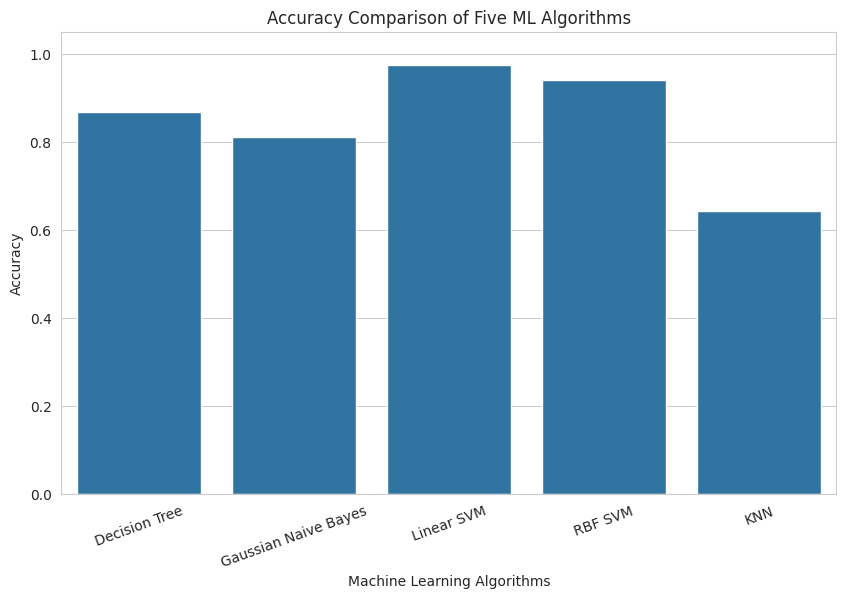

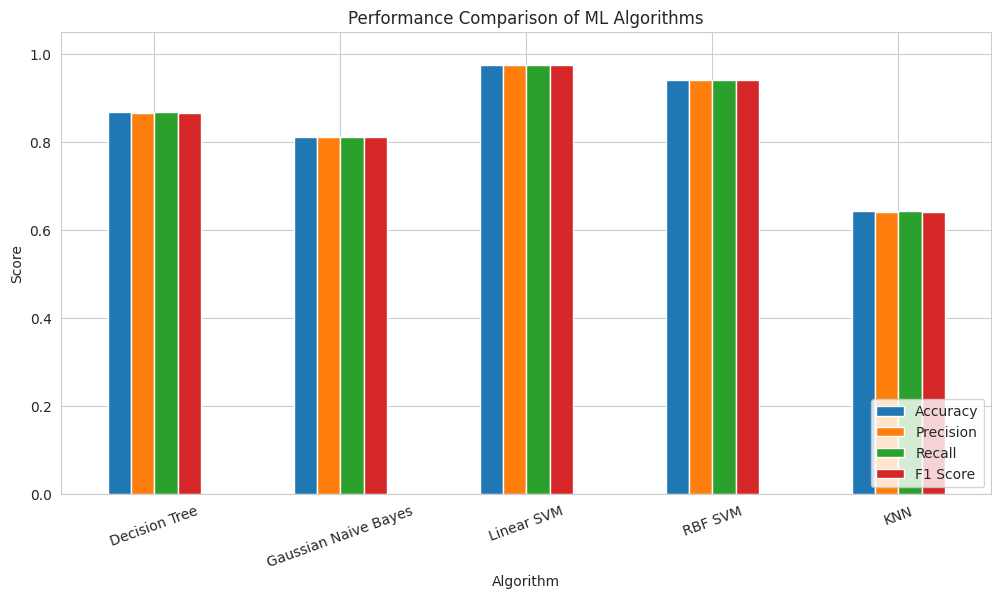


Best Performing Algorithm: Linear SVM


In [15]:

# Step 11: Compare All Five Machine Learning Algorithms

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Store all model predictions
model_predictions = {
    'Decision Tree': dt_predictions,
    'Gaussian Naive Bayes': nb_predictions,
    'Linear SVM': linear_predictions,
    'RBF SVM': rbf_predictions,
    'KNN': knn_predictions
}

# Calculate evaluation metrics
results = []

for model_name, predictions in model_predictions.items():

    results.append({
        'Algorithm': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, average='weighted'),
        'Recall': recall_score(y_test, predictions, average='weighted'),
        'F1 Score': f1_score(y_test, predictions, average='weighted')
    })

# Create comparison DataFrame
results_df = pd.DataFrame(results)

print("Performance Comparison of Machine Learning Algorithms")
display(results_df.round(4))

# Visualize model accuracy
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x='Algorithm',
    y='Accuracy'
)

plt.title('Accuracy Comparison of Five ML Algorithms')
plt.xlabel('Machine Learning Algorithms')
plt.ylabel('Accuracy')
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.show()

# Visualize all evaluation metrics
results_df.set_index('Algorithm').plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Performance Comparison of ML Algorithms')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(loc='lower right')
plt.show()

# Identify the best performing model based on accuracy
best_model_name = results_df.loc[
    results_df['Accuracy'].idxmax(), 'Algorithm'
]

print("\nBest Performing Algorithm:", best_model_name)


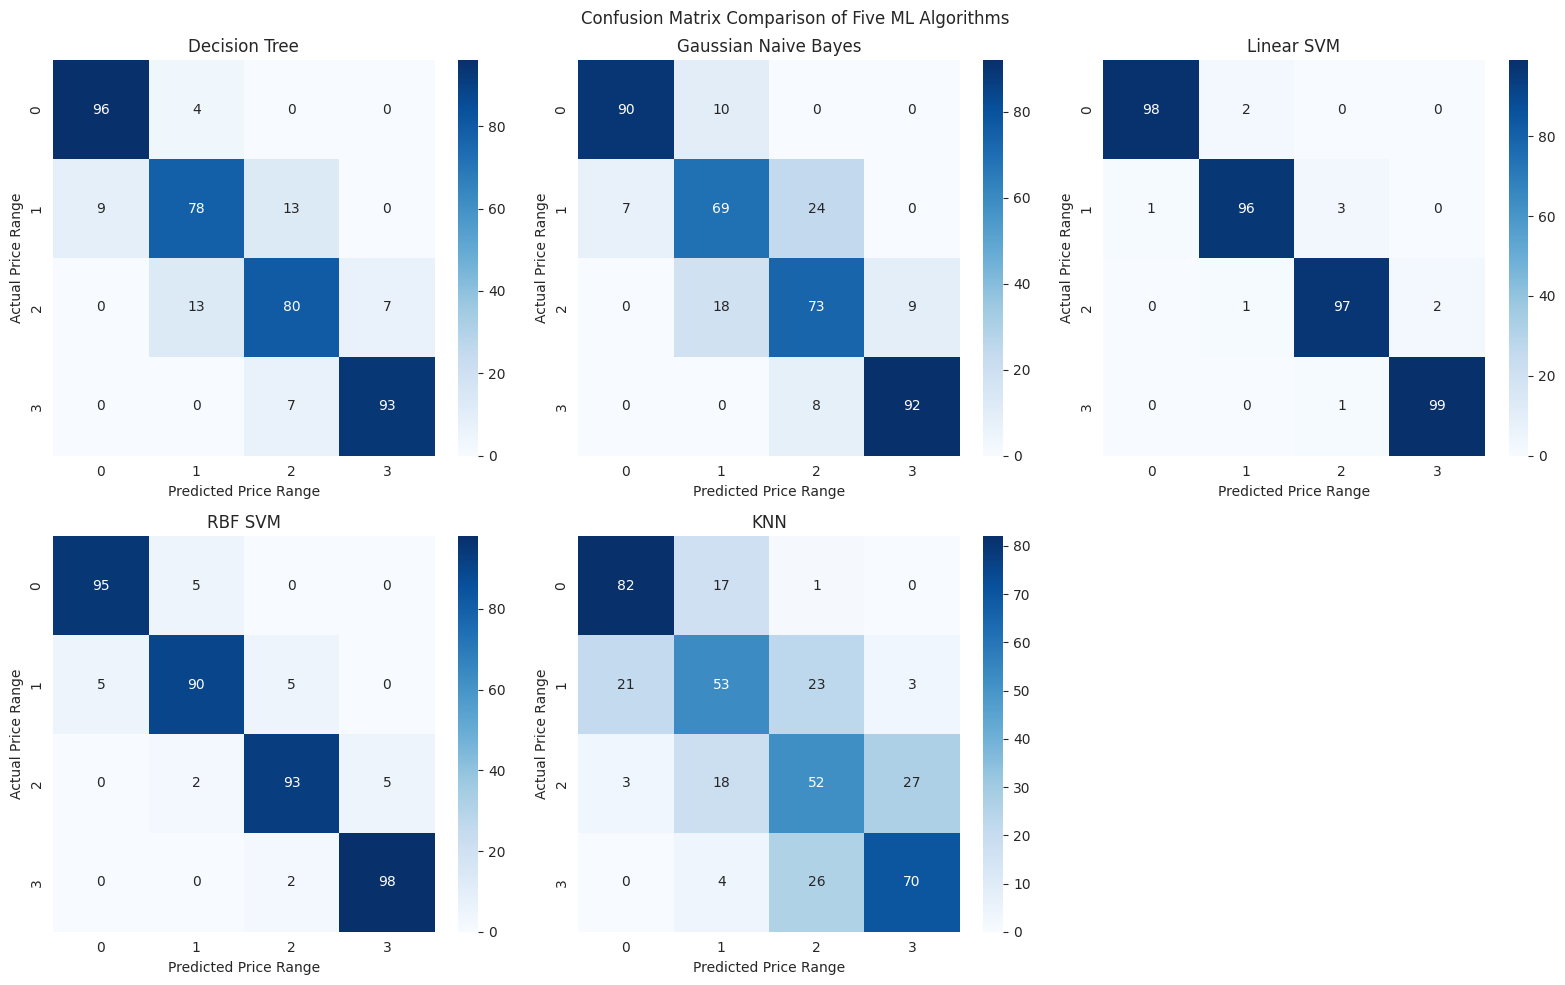

In [16]:

# Step 12: Confusion Matrices for All Five Algorithms

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Store model predictions
model_predictions = {
    'Decision Tree': dt_predictions,
    'Gaussian Naive Bayes': nb_predictions,
    'Linear SVM': linear_predictions,
    'RBF SVM': rbf_predictions,
    'KNN': knn_predictions
}

# Plot confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (model_name, predictions) in enumerate(model_predictions.items()):

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=[0, 1, 2, 3],
        yticklabels=[0, 1, 2, 3],
        ax=axes[i]
    )

    axes[i].set_title(model_name)
    axes[i].set_xlabel('Predicted Price Range')
    axes[i].set_ylabel('Actual Price Range')

# Remove unused sixth plot
fig.delaxes(axes[5])

plt.suptitle('Confusion Matrix Comparison of Five ML Algorithms')
plt.tight_layout()
plt.show()


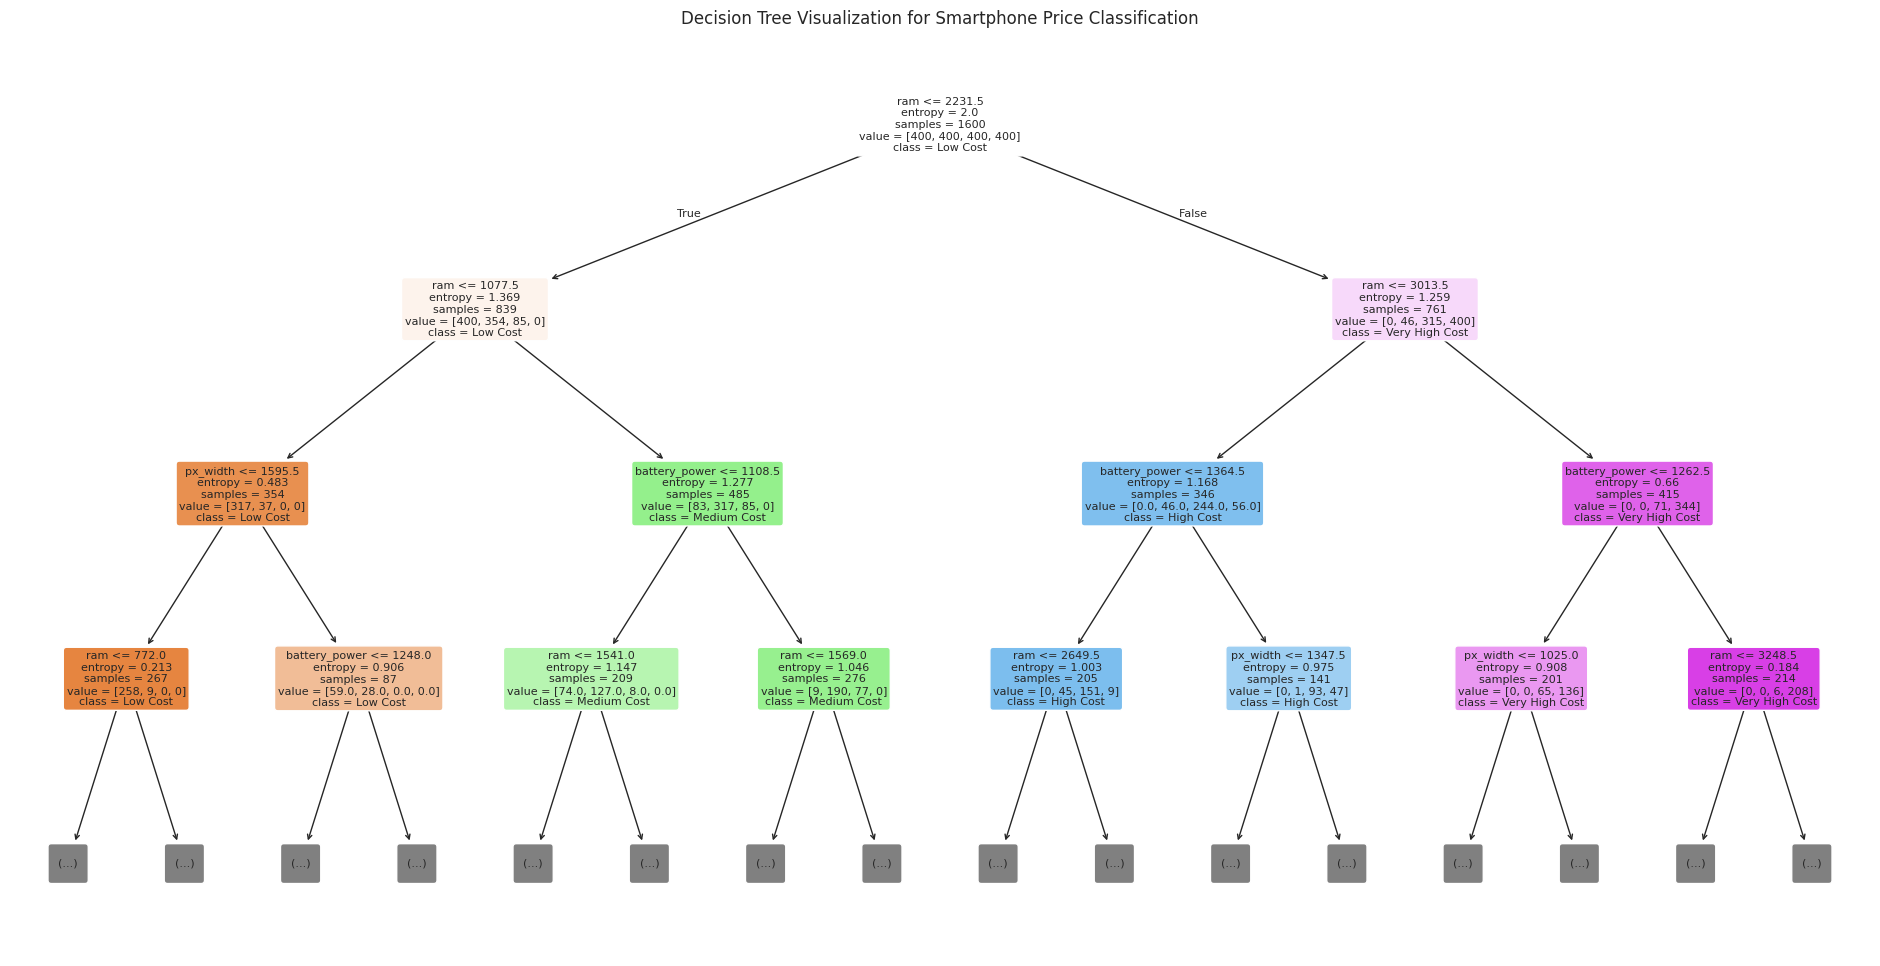

In [17]:

# Step 13: Decision Tree Visualization

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Set figure size
plt.figure(figsize=(24, 12))

# Visualize the trained Decision Tree
plot_tree(
    best_dt,
    feature_names=X.columns,
    class_names=['Low Cost', 'Medium Cost', 'High Cost', 'Very High Cost'],
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3
)

plt.title('Decision Tree Visualization for Smartphone Price Classification')
plt.show()


Feature Importance Ranking:


,Feature,Importance
13,ram,0.671290
0,battery_power,0.104789
12,px_width,0.096537
11,px_height,0.058813
8,mobile_wt,0.013177
10,pc,0.009665
14,sc_h,0.009599
6,int_memory,0.006696
15,sc_w,0.005239
16,talk_time,0.005147


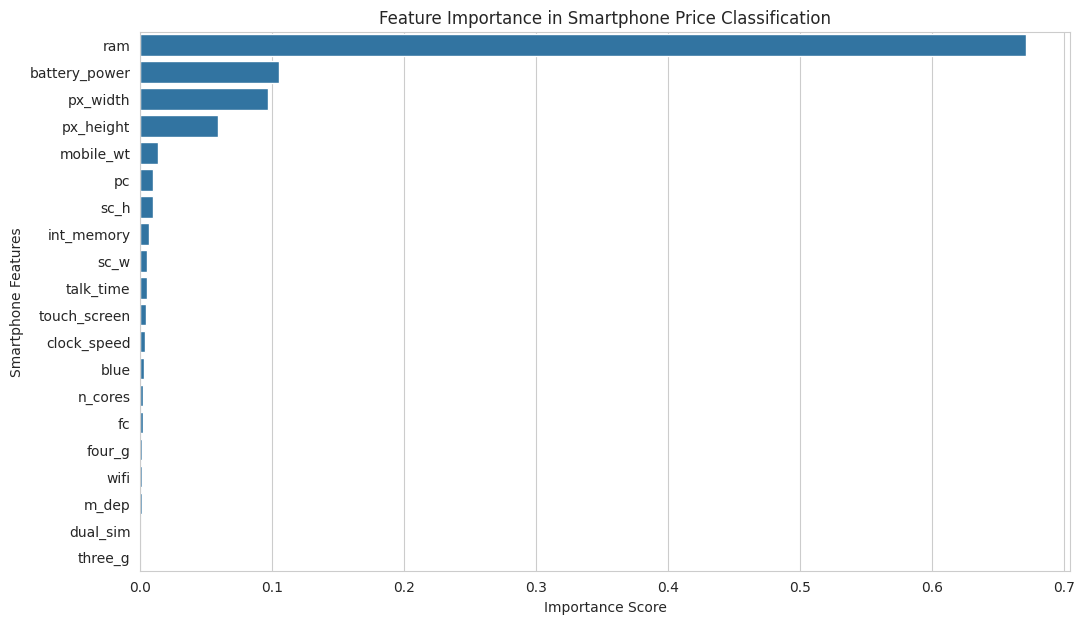


Top 5 Important Features:


,Feature,Importance
13,ram,0.671290
0,battery_power,0.104789
12,px_width,0.096537
11,px_height,0.058813
8,mobile_wt,0.013177


In [18]:

# Step 14: Feature Importance Analysis

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importance from Decision Tree
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_dt.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Feature Importance Ranking:")
display(feature_importance)

# Visualize feature importance
plt.figure(figsize=(12, 7))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance in Smartphone Price Classification')
plt.xlabel('Importance Score')
plt.ylabel('Smartphone Features')
plt.show()

# Display top 5 important features
print("\nTop 5 Important Features:")
display(feature_importance.head(5))


In [19]:

# Step 15: Interactive Smartphone Price Tier Prediction

import pandas as pd
from IPython.display import display
import ipywidgets as widgets

# Define smartphone input fields
features = {
    'battery_power': (1000, 2000, 1500),
    'blue': (0, 1, 1),
    'clock_speed': (0.5, 3.0, 1.5),
    'dual_sim': (0, 1, 1),
    'fc': (0, 19, 5),
    'four_g': (0, 1, 1),
    'int_memory': (2, 64, 32),
    'm_dep': (0.1, 1.0, 0.5),
    'mobile_wt': (80, 200, 150),
    'n_cores': (1, 8, 4),
    'pc': (0, 20, 10),
    'px_height': (0, 1960, 800),
    'px_width': (500, 1998, 1200),
    'ram': (256, 3998, 2000),
    'sc_h': (5, 19, 12),
    'sc_w': (0, 18, 6),
    'talk_time': (2, 20, 10),
    'three_g': (0, 1, 1),
    'touch_screen': (0, 1, 1),
    'wifi': (0, 1, 1)
}

# Create input widgets
input_widgets = {}

for feature, (minimum, maximum, default) in features.items():
    input_widgets[feature] = widgets.IntSlider(
        value=default,
        min=minimum,
        max=maximum,
        description=feature,
        style={'description_width': 'initial'},
        layout=widgets.Layout(width='500px')
    )

# Model selection
model_dropdown = widgets.Dropdown(
    options=[
        'Decision Tree',
        'Gaussian Naive Bayes',
        'Linear SVM',
        'RBF SVM',
        'KNN'
    ],
    value='RBF SVM',
    description='Select Model:'
)

# Prediction button
predict_button = widgets.Button(
    description='Predict Price Range',
    button_style='success'
)

output = widgets.Output()

def predict_price(b):
    with output:
        output.clear_output()

        # Collect input values
        input_data = pd.DataFrame(
            [[input_widgets[col].value for col in X.columns]],
            columns=X.columns
        )

        # Select trained model
        selected_model = model_dropdown.value

        if selected_model == 'Decision Tree':
            prediction = best_dt.predict(input_data)

        elif selected_model == 'Gaussian Naive Bayes':
            prediction = nb_model.predict(scaler.transform(input_data))

        elif selected_model == 'Linear SVM':
            prediction = best_linear_svm.predict(scaler.transform(input_data))

        elif selected_model == 'RBF SVM':
            prediction = best_rbf_svm.predict(scaler.transform(input_data))

        else:
            prediction = best_knn.predict(scaler.transform(input_data))

        price_categories = {
            0: 'Low Cost',
            1: 'Medium Cost',
            2: 'High Cost',
            3: 'Very High Cost'
        }

        print("Selected Algorithm:", selected_model)
        print("Predicted Price Range:", price_categories[prediction[0]])

predict_button.on_click(predict_price)

# Display interactive interface
display(widgets.VBox([
    widgets.HTML("<h3>Smartphone Price Range Prediction System</h3>"),
    model_dropdown,
    *input_widgets.values(),
    predict_button,
    output
]))


FINAL MODEL PERFORMANCE COMPARISON


,Algorithm,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
0,Decision Tree,86.75,86.63,86.75,86.66
1,Gaussian Naive Bayes,81.00,81.13,81.00,81.05
2,Linear SVM,97.50,97.50,97.50,97.50
3,RBF SVM,94.00,93.98,94.00,93.98
4,KNN,64.25,63.99,64.25,64.08



BEST PERFORMING ALGORITHM
Algorithm: Linear SVM
Test Accuracy: 97.5 %


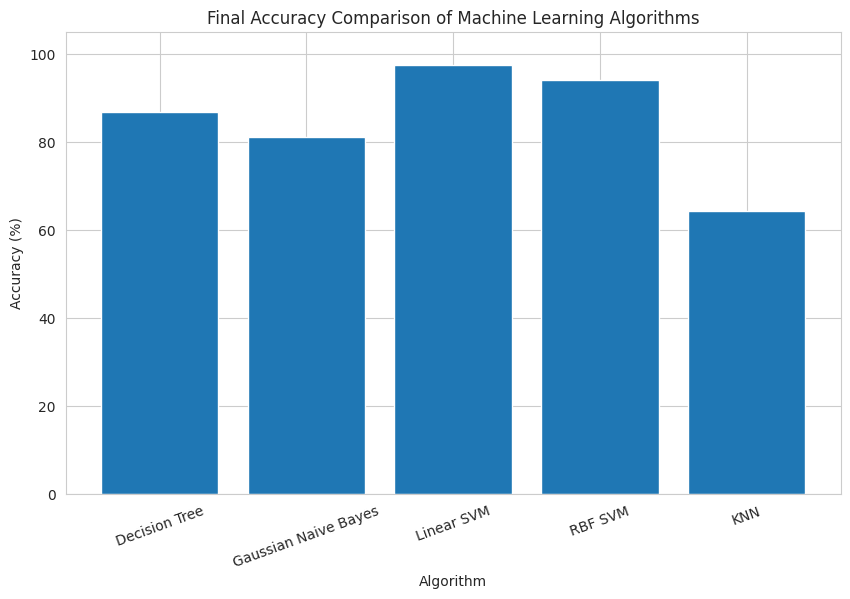


Final results saved successfully!


In [21]:

# Step 16: Final Results and Project Conclusion

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt

# Collect final model results
final_results = []

models = {
    'Decision Tree': dt_predictions,
    'Gaussian Naive Bayes': nb_predictions,
    'Linear SVM': linear_predictions,
    'RBF SVM': rbf_predictions,
    'KNN': knn_predictions
}

for name, predictions in models.items():

    final_results.append({
        'Algorithm': name,
        'Accuracy (%)': accuracy_score(y_test, predictions) * 100,
        'Precision (%)': precision_score(y_test, predictions, average='weighted') * 100,
        'Recall (%)': recall_score(y_test, predictions, average='weighted') * 100,
        'F1 Score (%)': f1_score(y_test, predictions, average='weighted') * 100
    })

# Create final comparison table
final_results_df = pd.DataFrame(final_results)

final_results_df = final_results_df.round(2)

print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 60)
display(final_results_df)

# Identify best model
best_index = final_results_df['Accuracy (%)'].idxmax()
best_algorithm = final_results_df.loc[best_index, 'Algorithm']
best_accuracy = final_results_df.loc[best_index, 'Accuracy (%)']

print("\nBEST PERFORMING ALGORITHM")
print("=" * 60)
print("Algorithm:", best_algorithm)
print("Test Accuracy:", best_accuracy, "%")

# Plot final accuracy comparison
plt.figure(figsize=(10, 6))

plt.bar(
    final_results_df['Algorithm'],
    final_results_df['Accuracy (%)']
)

plt.title('Final Accuracy Comparison of Machine Learning Algorithms')
plt.xlabel('Algorithm')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 105)
plt.xticks(rotation=20)
plt.show()

# Save final results
final_results_df.to_csv(
    'smartphone_price_classification_results.csv',
    index=False
)

print("\nFinal results saved successfully!")


In [22]:

!pip install -q gradio
print("Gradio installed successfully!")


Gradio installed successfully!


In [ ]:

# Smartphone Price Range Tier Categorization
# Interactive Web Application using Gradio

import gradio as gr
import pandas as pd

# Available trained models
trained_models = {
    "Decision Tree": best_dt,
    "Gaussian Naive Bayes": nb_model,
    "Linear SVM": best_linear_svm,
    "RBF SVM": best_rbf_svm,
    "K-Nearest Neighbors": best_knn
}

# Price categories
price_categories = {
    0: "Low Cost",
    1: "Medium Cost",
    2: "High Cost",
    3: "Very High Cost"
}

# Prediction function
def predict_price(model_name, *values):

    input_data = pd.DataFrame(
        [values],
        columns=X.columns
    )

    selected_model = trained_models[model_name]

    if model_name == "Decision Tree":
        prediction = selected_model.predict(input_data)
    else:
        scaled_data = scaler.transform(input_data)
        prediction = selected_model.predict(scaled_data)

    predicted_class = int(prediction[0])

    return (
        f"Predicted Price Category: "
        f"{price_categories[predicted_class]}\n\n"
        f"Price Range Class: {predicted_class}\n"
        f"Selected Algorithm: {model_name}"
    )

# Create input fields using dataset feature names
input_fields = []

for feature in X.columns:
    default_value = float(X[feature].median())

    input_fields.append(
        gr.Number(
            label=feature,
            value=default_value
        )
    )

# Create web application
with gr.Blocks(theme=gr.themes.Soft()) as demo:

    gr.Markdown(
        """
        # 📱 Smartphone Price Range Predictor

        ### Machine Learning-Based Price Tier Categorization

        Enter smartphone specifications and select a machine
        learning algorithm to predict its price category.

        **Categories:** Low Cost | Medium Cost | High Cost | Very High Cost
        """
    )

    model_choice = gr.Dropdown(
        choices=list(trained_models.keys()),
        value="RBF SVM",
        label="Select Machine Learning Algorithm"
    )

    gr.Markdown("### Smartphone Specifications")

    with gr.Row():
        with gr.Column():
            for field in input_fields[:10]:
                field.render()

        with gr.Column():
            for field in input_fields[10:]:
                field.render()

    predict_button = gr.Button(
        "Predict Price Range",
        variant="primary"
    )

    prediction_output = gr.Textbox(
        label="Prediction Result",
        lines=4
    )

    predict_button.click(
        fn=predict_price,
        inputs=[model_choice] + input_fields,
        outputs=prediction_output
    )

    gr.Markdown(
        """
        ---
        **Project:** Smartphone Price Range Tier Categorization

        **Algorithms:** Decision Tree, Gaussian Naive Bayes,
        Linear SVM, RBF SVM and KNN.

        **Technology:** Python, Scikit-learn, Gradio and Google Colab.
        """
    )

# Launch public demo
demo.launch(share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://969aefa0465b74d309.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
